# <center>Taller de Aprendizaje Automático</center>

## Árboles y Ensambles sobre Higgs

Este notebook toma como base los **modelos** trabajados en `docs/taller3_demanda_de_bicicletas.ipynb`, pero descarta todo el análisis exploratorio y preprocesamiento específico de ese taller. Acá se reutilizan directamente los datos ya procesados del desafío Higgs y se adapta la experimentación a un problema de **clasificación binaria**.

## Sub objetivos

- volver a cargar los datos procesados desde `data/higgs-boson/processed/i1`
- trabajar con un split `train/validation` estratificado, igual que en el notebook de NN
- probar los modelos del taller 3 adaptados a clasificación:
  - `DecisionTreeClassifier`
  - ajuste fino de árbol por `max_depth`
  - `RandomForestClassifier`
  - `XGBClassifier`
- comparar los modelos por `ROC AUC` y métricas de clasificación sobre validación

## Introducción

El taller 3 original está orientado a predicción de demanda con árboles y ensambles en un problema de regresión. En este notebook se conserva la idea metodológica de ese material, pero se cambia el foco a Higgs, donde el objetivo es distinguir entre `background` (`b`) y `signal` (`s`).

Por eso:

- no se repite el análisis de variables del taller original,
- no se reimplementa el preprocesamiento de bicicletas,
- y se usa como métrica principal `ROC AUC`, que es más apropiada para clasificación binaria con clases desbalanceadas.

## Preparación de datos

In [1]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42
np.random.seed(SEED)

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBClassifier = None
    XGBOOST_AVAILABLE = False
    print("xgboost no está instalado. Para ejecutar la sección correspondiente usar `%pip install xgboost`.")


def find_processed_data_dir() -> Path:
    """Busca el directorio de datos procesados desde el cwd actual."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "data" / "higgs-boson" / "processed" / "i1"
        if candidate.exists():
            return candidate
    raise FileNotFoundError("No se encontró data/higgs-boson/processed/i1")


data_dir = find_processed_data_dir()
print(f"Data dir: {data_dir}")

Data dir: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/i1


In [2]:
X_labeled_full = pd.read_csv(data_dir / "X_train_processed.csv")
y_labeled_full = pd.read_csv(data_dir / "y_train.csv")
X_test_processed = pd.read_csv(data_dir / "X_test_processed.csv")
test_event_id = pd.read_csv(data_dir / "test_event_id.csv")

if list(X_labeled_full.columns) != list(X_test_processed.columns):
    raise ValueError("Las columnas de train y X_test_processed no coinciden.")

if len(X_test_processed) != len(test_event_id):
    raise ValueError("La cantidad de filas de X_test_processed y test_event_id no coincide.")

X = X_labeled_full.astype(np.float32)
y = y_labeled_full["Label"].map({"b": 0, "s": 1}).astype(np.int8)
X_test = X_test_processed.astype(np.float32)

print(f"X labeled shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"X_test_processed shape: {X_test.shape}")
print(f"test_event_id shape: {test_event_id.shape}")
print("Class distribution:")
display(y.value_counts().rename(index={0: "b", 1: "s"}))

X labeled shape: (250000, 26)
y shape: (250000,)
X_test_processed shape: (550000, 26)
test_event_id shape: (550000, 1)
Class distribution:


Label
b    164333
s     85667
Name: count, dtype: int64

## Train / validation split

Se conserva la misma lógica que en `NN_extendido.ipynb`: un split estratificado para dejar un conjunto de validación externo y reservar la validación cruzada para comparar modelos únicamente dentro del conjunto de entrenamiento.

In [3]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=SEED,
    stratify=y,
)

neg_count = int((y_train == 0).sum())
pos_count = int((y_train == 1).sum())
scale_pos_weight = float(neg_count / pos_count)

print(f"Train shape: {X_train.shape}")
print(f"Valid shape: {X_valid.shape}")
print(f"External test shape: {X_test.shape}")
print(f"scale_pos_weight sugerido para XGBoost: {scale_pos_weight:.4f}")

Train shape: (225000, 26)
Valid shape: (25000, 26)
External test shape: (550000, 26)
scale_pos_weight sugerido para XGBoost: 1.9183


## Helpers

Las utilidades siguientes unifican la evaluación entre modelos. El criterio principal es `ROC AUC` en validación cruzada y en el holdout externo.

In [4]:
def make_cv() -> StratifiedKFold:
    return StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def predict_scores(model, X_frame: pd.DataFrame) -> np.ndarray:
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_frame)[:, 1]
    if hasattr(model, "decision_function"):
        return model.decision_function(X_frame)
    raise AttributeError("El modelo no expone ni predict_proba ni decision_function.")


def evaluate_classifier(model, X_frame: pd.DataFrame, y_true: pd.Series, name: str) -> dict:
    y_pred = model.predict(X_frame)
    y_score = predict_scores(model, X_frame)
    return {
        "model": name,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "auc": float(roc_auc_score(y_true, y_score)),
    }


def summarize_cv_scores(name: str, cv_scores: dict) -> dict:
    train_auc = cv_scores["train_score"]
    valid_auc = cv_scores["test_score"]
    return {
        "model": name,
        "cv_train_auc_mean": float(train_auc.mean()),
        "cv_train_auc_std": float(train_auc.std()),
        "cv_valid_auc_mean": float(valid_auc.mean()),
        "cv_valid_auc_std": float(valid_auc.std()),
        "cv_gap_auc": float(train_auc.mean() - valid_auc.mean()),
    }


def plot_cv_auc(cv_scores: dict, title: str) -> None:
    train_auc = cv_scores["train_score"]
    valid_auc = cv_scores["test_score"]
    folds = np.arange(1, len(train_auc) + 1)

    plt.figure(figsize=(9, 5))
    plt.plot(folds, train_auc, ".-", label="train AUC")
    plt.plot(folds, valid_auc, ".-", label="valid AUC")
    plt.fill_between(
        folds,
        train_auc.mean() - train_auc.std(),
        train_auc.mean() + train_auc.std(),
        alpha=0.2,
    )
    plt.fill_between(
        folds,
        valid_auc.mean() - valid_auc.std(),
        valid_auc.mean() + valid_auc.std(),
        alpha=0.2,
    )
    plt.xlabel("Fold")
    plt.ylabel("ROC AUC")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()


def plot_top_feature_importances(model, feature_names: pd.Index, title: str, top_n: int = 15) -> None:
    if not hasattr(model, "feature_importances_"):
        print(f"{title}: el modelo no expone feature_importances_.")
        return

    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": model.feature_importances_,
    }).sort_values("importance", ascending=False).head(top_n)

    plt.figure(figsize=(9, 5))
    plt.barh(importance_df["feature"][::-1], importance_df["importance"][::-1], color="#4C72B0")
    plt.xlabel("Importance")
    plt.title(title)
    plt.grid(axis="x", alpha=0.3)
    plt.show()


def display_confusion_matrix(model, X_frame: pd.DataFrame, y_true: pd.Series, title: str) -> None:
    disp = ConfusionMatrixDisplay.from_predictions(
        y_true,
        model.predict(X_frame),
        display_labels=["b", "s"],
        cmap="Blues",
        colorbar=False,
    )
    disp.ax_.set_title(title)
    plt.show()

## Parte 1 - Árbol de decisión por defecto

Se empieza con un `DecisionTreeClassifier` sencillo, análogo al árbol del taller 3. La diferencia es que acá se usa `ROC AUC` y se agrega `class_weight="balanced"` porque Higgs es un problema binario con clases desbalanceadas.

Resumen del árbol de decisión por defecto:


,model,cv_train_auc_mean,cv_train_auc_std,cv_valid_auc_mean,cv_valid_auc_std,cv_gap_auc,accuracy,precision,recall,f1,auc
0,decision_tree_default,1.0,0.0,0.7358,0.0016,0.2642,0.7624,0.654,0.6513,0.6527,0.7358


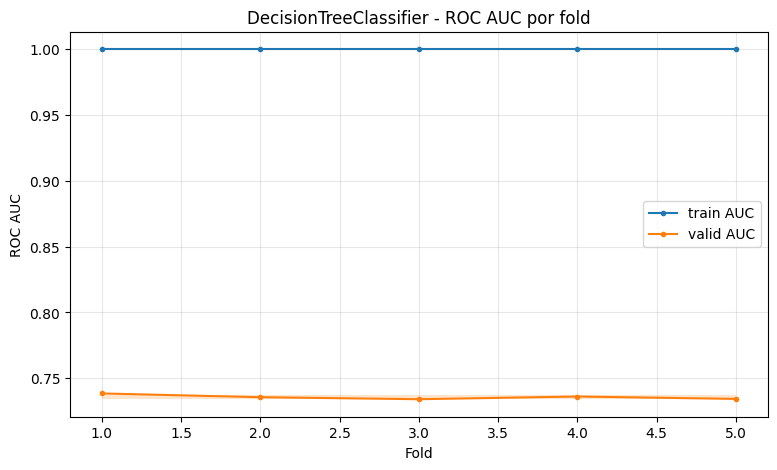

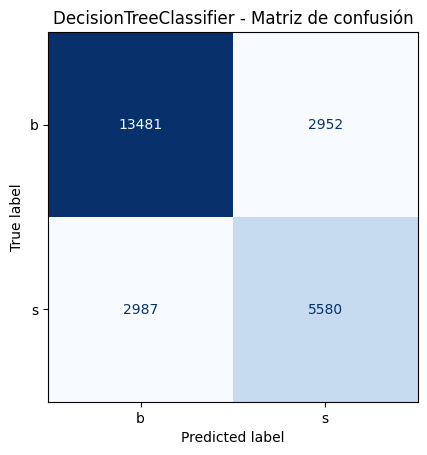

In [5]:
decision_tree = DecisionTreeClassifier(
    random_state=SEED,
    class_weight="balanced",
)

decision_tree_scores = cross_validate(
    decision_tree,
    X_train,
    y_train,
    cv=make_cv(),
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=-1,
)

decision_tree.fit(X_train, y_train)
decision_tree_eval = evaluate_classifier(decision_tree, X_valid, y_valid, "decision_tree_default")
decision_tree_cv_summary = summarize_cv_scores("decision_tree_default", decision_tree_scores)

decision_tree_summary_df = pd.DataFrame([{**decision_tree_cv_summary, **decision_tree_eval}])

print("Resumen del árbol de decisión por defecto:")
display(decision_tree_summary_df.round(4))
plot_cv_auc(decision_tree_scores, "DecisionTreeClassifier - ROC AUC por fold")
display_confusion_matrix(decision_tree, X_valid, y_valid, "DecisionTreeClassifier - Matriz de confusión")

## Parte 2 - Ajuste fino del árbol por `max_depth`

Siguiendo la lógica del taller 3, la búsqueda de hiperparámetros se concentra en `max_depth`. La idea es medir cómo cambia el compromiso entre ajuste y generalización a medida que el árbol gana complejidad.

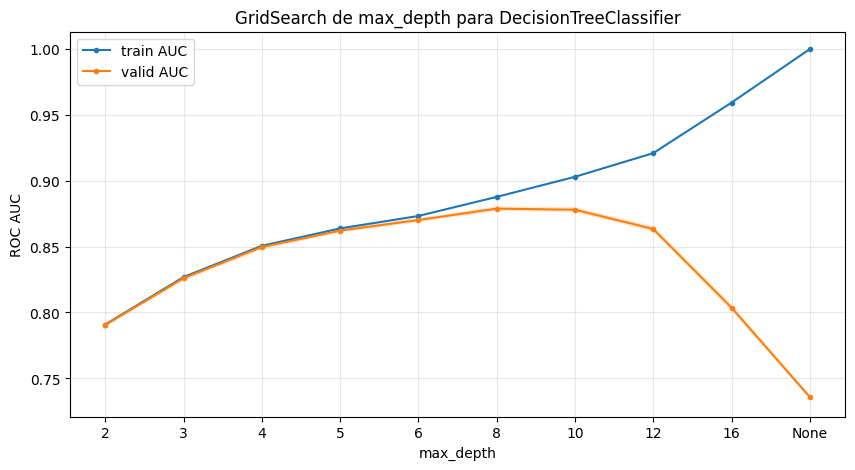

Resultados completos del grid search del árbol:


,depth_label,mean_train_score,std_train_score,mean_test_score,std_test_score,rank_test_score
0,2,0.7908,0.0004,0.7904,0.0014,9
1,3,0.8268,0.0005,0.8260,0.0019,7
2,4,0.8506,0.0003,0.8497,0.0020,6
3,5,0.8638,0.0004,0.8621,0.0016,5
4,6,0.8732,0.0005,0.8702,0.0016,3
5,8,0.8877,0.0004,0.8788,0.0017,1
6,10,0.9030,0.0004,0.8780,0.0020,2
7,12,0.9210,0.0006,0.8634,0.0020,4
8,16,0.9594,0.0004,0.8036,0.0024,8
9,None,1.0000,0.0000,0.7358,0.0016,10


Mejor árbol encontrado:


,model,accuracy,precision,recall,f1,auc,best_cv_auc,best_max_depth
0,decision_tree_tuned,0.8018,0.675,0.8132,0.7377,0.8768,0.8788,8


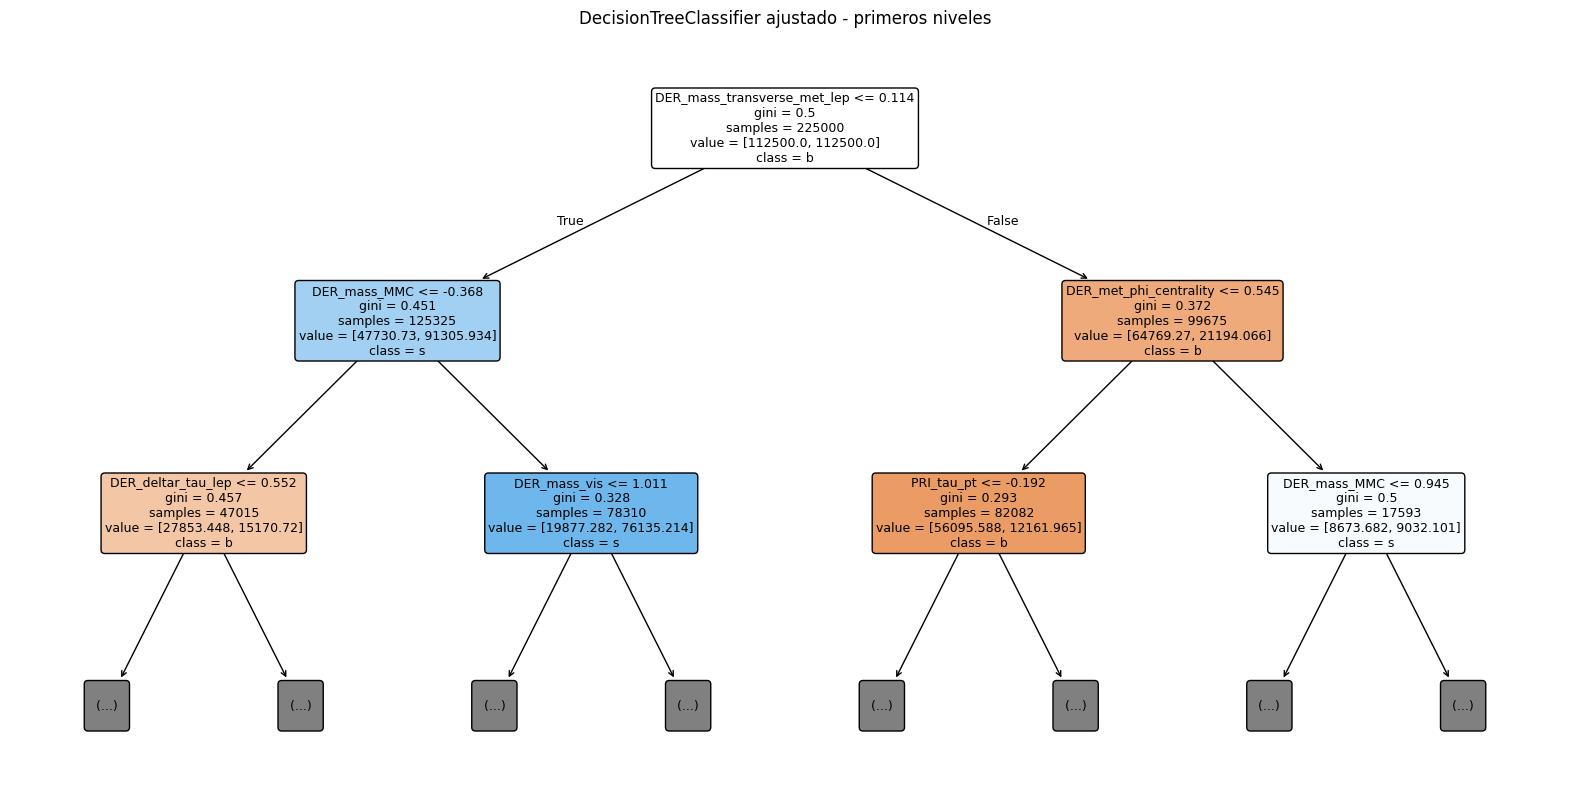

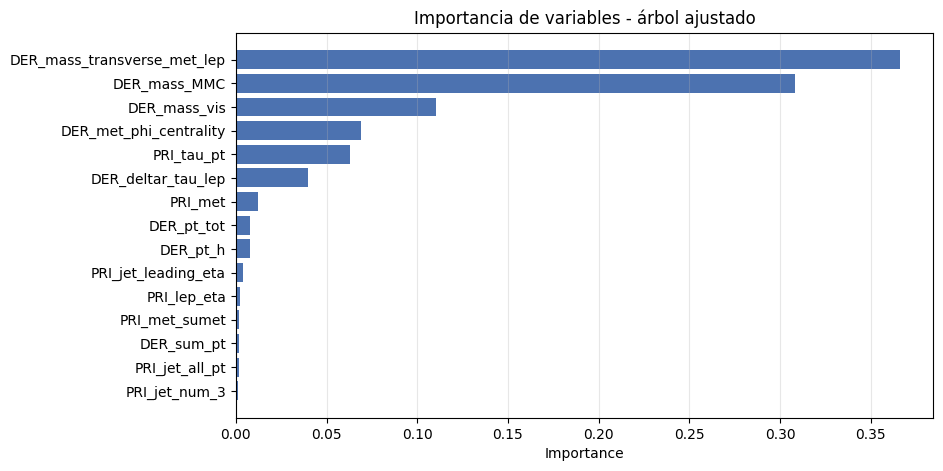

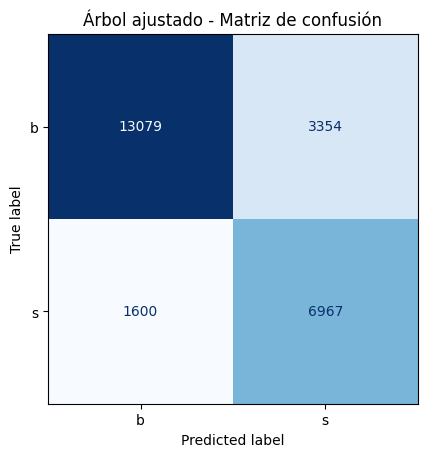

In [6]:
depth_grid = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10, 12, 16, None],
}

base_tree = DecisionTreeClassifier(
    random_state=SEED,
    class_weight="balanced",
)

tree_grid = GridSearchCV(
    estimator=base_tree,
    param_grid=depth_grid,
    cv=make_cv(),
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=-1,
)

tree_grid.fit(X_train, y_train)

tree_results_df = pd.DataFrame(tree_grid.cv_results_)
tree_results_df["depth_label"] = tree_results_df["param_max_depth"].astype(str).replace({"None": "None"})
tree_results_df["depth_order"] = tree_results_df["param_max_depth"].apply(lambda value: 999 if value is None else int(value))
tree_results_df = tree_results_df.sort_values("depth_order").reset_index(drop=True)

x_positions = np.arange(len(tree_results_df))

plt.figure(figsize=(10, 5))
plt.plot(x_positions, tree_results_df["mean_train_score"], ".-", label="train AUC")
plt.plot(x_positions, tree_results_df["mean_test_score"], ".-", label="valid AUC")
plt.fill_between(
    x_positions,
    tree_results_df["mean_train_score"] - tree_results_df["std_train_score"],
    tree_results_df["mean_train_score"] + tree_results_df["std_train_score"],
    alpha=0.2,
)
plt.fill_between(
    x_positions,
    tree_results_df["mean_test_score"] - tree_results_df["std_test_score"],
    tree_results_df["mean_test_score"] + tree_results_df["std_test_score"],
    alpha=0.2,
)
plt.xticks(x_positions, tree_results_df["depth_label"])
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("GridSearch de max_depth para DecisionTreeClassifier")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

best_tree = tree_grid.best_estimator_
best_tree_eval = evaluate_classifier(best_tree, X_valid, y_valid, "decision_tree_tuned")
best_tree_summary_df = pd.DataFrame([{
    **best_tree_eval,
    "best_cv_auc": float(tree_grid.best_score_),
    "best_max_depth": str(tree_grid.best_params_["max_depth"]),
}])

print("Resultados completos del grid search del árbol:")
display(
    tree_results_df[[
        "depth_label",
        "mean_train_score",
        "std_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
    ]].round(4)
)

print("Mejor árbol encontrado:")
display(best_tree_summary_df.round(4))

plt.figure(figsize=(20, 10))
plot_tree(
    best_tree,
    feature_names=X_train.columns,
    class_names=["b", "s"],
    max_depth=2,
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("DecisionTreeClassifier ajustado - primeros niveles")
plt.show()

plot_top_feature_importances(best_tree, X_train.columns, "Importancia de variables - árbol ajustado")
display_confusion_matrix(best_tree, X_valid, y_valid, "Árbol ajustado - Matriz de confusión")

## Parte 3 - Random Forest

El segundo modelo del taller es `RandomForest`. Acá se adapta a clasificación con `RandomForestClassifier`, manteniendo el esquema de validación cruzada y la comparación posterior sobre el holdout externo.

Resumen de RandomForestClassifier:


,model,cv_train_auc_mean,cv_train_auc_std,cv_valid_auc_mean,cv_valid_auc_std,cv_gap_auc,accuracy,precision,recall,f1,auc
0,random_forest,1.0,0.0,0.9015,0.0017,0.0985,0.8339,0.7953,0.6939,0.7412,0.8988


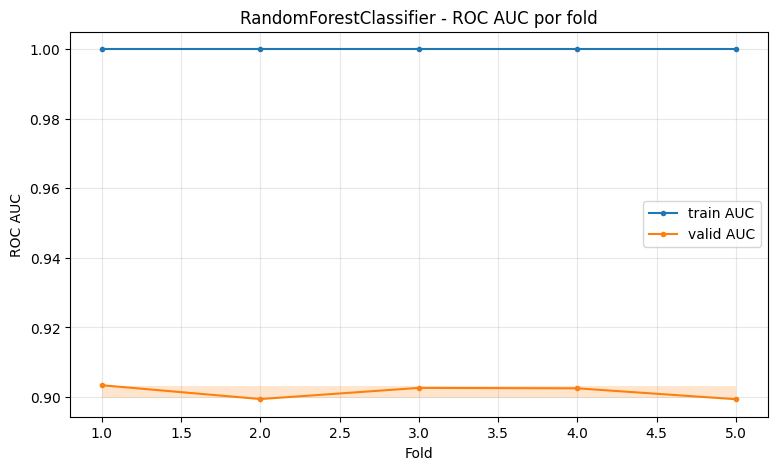

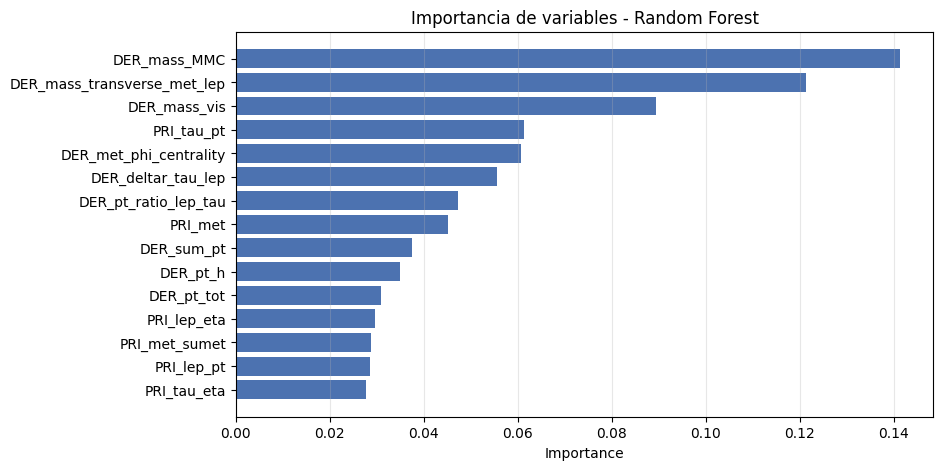

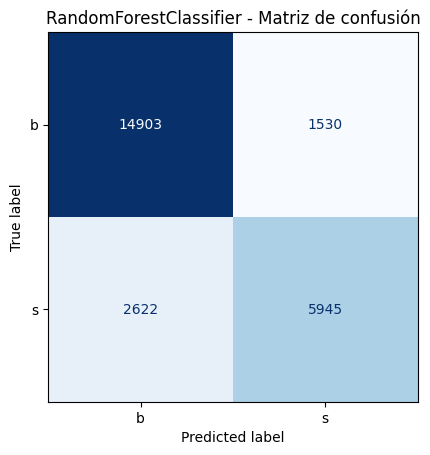

In [7]:
random_forest = RandomForestClassifier(
    random_state=SEED,
    n_jobs=-1,
    class_weight="balanced",
)

random_forest_scores = cross_validate(
    random_forest,
    X_train,
    y_train,
    cv=make_cv(),
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=-1,
)

random_forest.fit(X_train, y_train)
random_forest_eval = evaluate_classifier(random_forest, X_valid, y_valid, "random_forest")
random_forest_cv_summary = summarize_cv_scores("random_forest", random_forest_scores)
random_forest_summary_df = pd.DataFrame([{**random_forest_cv_summary, **random_forest_eval}])

print("Resumen de RandomForestClassifier:")
display(random_forest_summary_df.round(4))
plot_cv_auc(random_forest_scores, "RandomForestClassifier - ROC AUC por fold")
plot_top_feature_importances(random_forest, X_train.columns, "Importancia de variables - Random Forest")
display_confusion_matrix(random_forest, X_valid, y_valid, "RandomForestClassifier - Matriz de confusión")

## Parte 4 - XGBoost

El tercer modelo del taller es XGBoost. Como el entorno puede no tener `xgboost` instalado, la celda avisa explícitamente si falta la dependencia.

Para adaptarlo a Higgs se usa `XGBClassifier` con objetivo binario y `scale_pos_weight` para reflejar el desbalance de clases del conjunto de entrenamiento.

Resumen de XGBClassifier:


,model,cv_train_auc_mean,cv_train_auc_std,cv_valid_auc_mean,cv_valid_auc_std,cv_gap_auc,accuracy,precision,recall,f1,auc
0,xgboost,0.9229,0.0004,0.9075,0.0015,0.0154,0.8239,0.7081,0.8271,0.763,0.9051


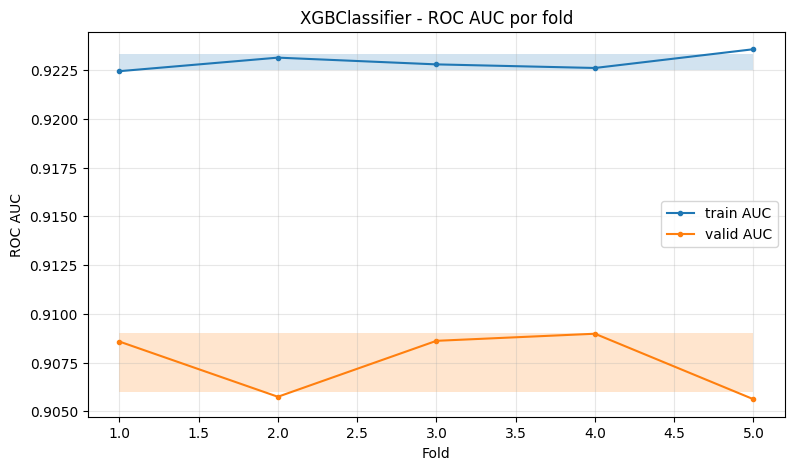

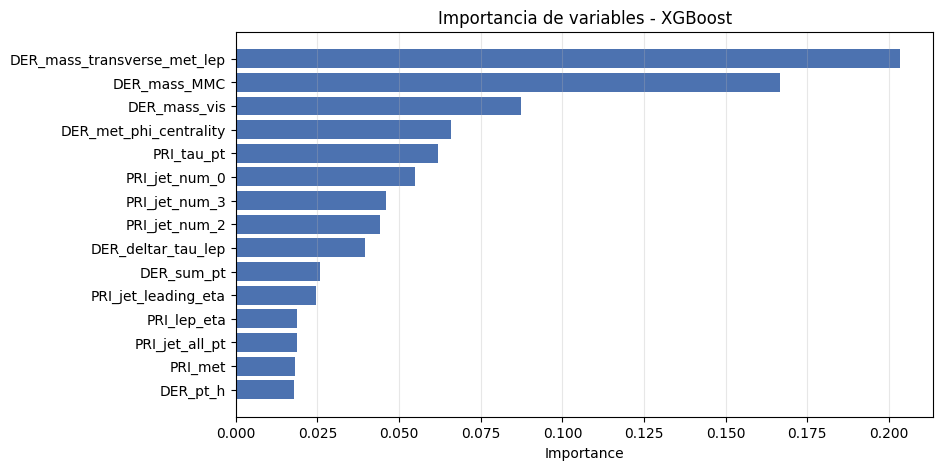

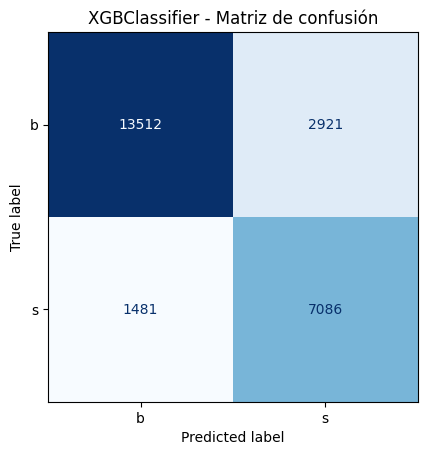

In [8]:
if not XGBOOST_AVAILABLE:
    print(
        "No se pudo importar xgboost. Esta parte se omite por ahora. "
        "Para ejecutarla, instalar con `%pip install xgboost`."
    )
else:
    xgboost_model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=SEED,
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=scale_pos_weight,
        n_jobs=-1,
    )

    xgboost_scores = cross_validate(
        xgboost_model,
        X_train,
        y_train,
        cv=make_cv(),
        scoring="roc_auc",
        return_train_score=True,
        n_jobs=-1,
    )

    xgboost_model.fit(X_train, y_train)
    xgboost_eval = evaluate_classifier(xgboost_model, X_valid, y_valid, "xgboost")
    xgboost_cv_summary = summarize_cv_scores("xgboost", xgboost_scores)
    xgboost_summary_df = pd.DataFrame([{**xgboost_cv_summary, **xgboost_eval}])

    print("Resumen de XGBClassifier:")
    display(xgboost_summary_df.round(4))
    plot_cv_auc(xgboost_scores, "XGBClassifier - ROC AUC por fold")
    plot_top_feature_importances(xgboost_model, X_train.columns, "Importancia de variables - XGBoost")
    display_confusion_matrix(xgboost_model, X_valid, y_valid, "XGBClassifier - Matriz de confusión")

## Parte 5 - Comparativa final

Esta sección junta los modelos del notebook y los ordena por `AUC` en validación. Si `xgboost` no está instalado, la comparativa se construye solo con los modelos disponibles.

Comparativa final de modelos basados en árboles:


,model,source,accuracy,precision,recall,f1,auc,cv_train_auc_mean,cv_valid_auc_mean,cv_gap_auc,delta_auc_vs_tree_default
0,xgboost,xgboost,0.8239,0.7081,0.8271,0.7630,0.9051,0.9229,0.9075,0.0154,0.1693
1,random_forest,random_forest,0.8339,0.7953,0.6939,0.7412,0.8988,1.0000,0.9015,0.0985,0.1629
2,decision_tree_tuned,tree_grid_max_depth=8,0.8018,0.6750,0.8132,0.7377,0.8768,0.8877,0.8788,0.0089,0.1410
3,decision_tree_default,decision_tree_default,0.7624,0.6540,0.6513,0.6527,0.7358,1.0000,0.7358,0.2642,0.0000


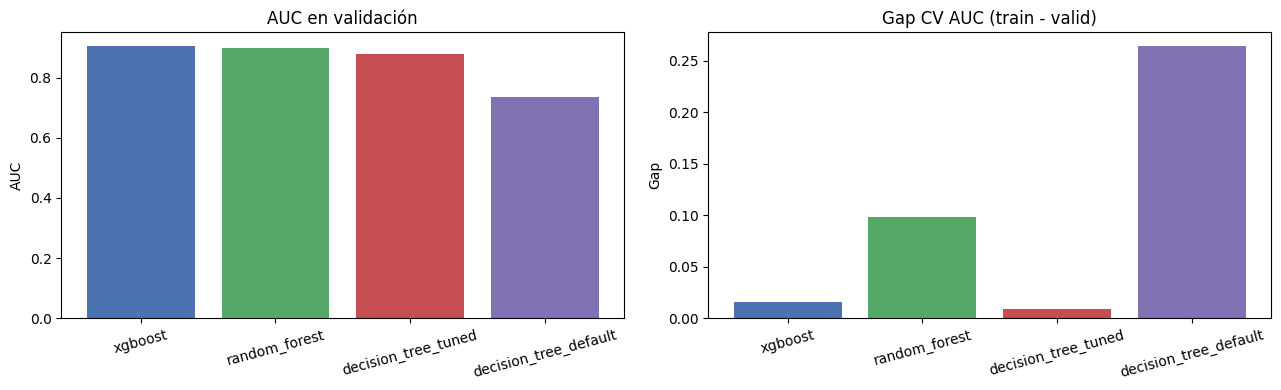

Mejor modelo por AUC en validación: xgboost (0.9051).
Delta AUC vs árbol por defecto: +0.1693.


In [9]:
model_summaries = [
    {**decision_tree_cv_summary, **decision_tree_eval, "source": "decision_tree_default"},
    {
        "model": "decision_tree_tuned",
        "cv_train_auc_mean": float(tree_grid.cv_results_["mean_train_score"][tree_grid.best_index_]),
        "cv_train_auc_std": float(tree_grid.cv_results_["std_train_score"][tree_grid.best_index_]),
        "cv_valid_auc_mean": float(tree_grid.cv_results_["mean_test_score"][tree_grid.best_index_]),
        "cv_valid_auc_std": float(tree_grid.cv_results_["std_test_score"][tree_grid.best_index_]),
        "cv_gap_auc": float(
            tree_grid.cv_results_["mean_train_score"][tree_grid.best_index_]
            - tree_grid.cv_results_["mean_test_score"][tree_grid.best_index_]
        ),
        **best_tree_eval,
        "source": f"tree_grid_max_depth={tree_grid.best_params_['max_depth']}",
    },
    {**random_forest_cv_summary, **random_forest_eval, "source": "random_forest"},
]

if XGBOOST_AVAILABLE and "xgboost_eval" in globals():
    model_summaries.append({**xgboost_cv_summary, **xgboost_eval, "source": "xgboost"})

comparison_df = pd.DataFrame(model_summaries).sort_values(
    ["auc", "cv_valid_auc_mean", "recall"],
    ascending=False,
).reset_index(drop=True)

baseline_auc = float(comparison_df.loc[comparison_df["model"] == "decision_tree_default", "auc"].iloc[0])
comparison_df["delta_auc_vs_tree_default"] = comparison_df["auc"] - baseline_auc

summary_columns = [
    "model",
    "source",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc",
    "cv_train_auc_mean",
    "cv_valid_auc_mean",
    "cv_gap_auc",
    "delta_auc_vs_tree_default",
]

print("Comparativa final de modelos basados en árboles:")
display(comparison_df[summary_columns].round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bar_colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B3"][: len(comparison_df)]

axes[0].bar(comparison_df["model"], comparison_df["auc"], color=bar_colors)
axes[0].set_title("AUC en validación")
axes[0].set_ylabel("AUC")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(comparison_df["model"], comparison_df["cv_gap_auc"], color=bar_colors)
axes[1].set_title("Gap CV AUC (train - valid)")
axes[1].set_ylabel("Gap")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

best_tree_model_row = comparison_df.iloc[0]
print(
    f"Mejor modelo por AUC en validación: {best_tree_model_row['model']} "
    f"({best_tree_model_row['auc']:.4f})."
)
print(
    f"Delta AUC vs árbol por defecto: {best_tree_model_row['delta_auc_vs_tree_default']:+.4f}."
)

## Parte 6 - Comparación con el mejor modelo de NN

Como referencia externa, esta sección carga el `best_optuna` exportado desde `NN_extendido.ipynb` en `models/NN_best_optuna` y lo evalúa sobre el mismo conjunto de validación usado en este notebook.

La comparación final queda entonces entre:

- el mejor modelo basado en árboles encontrado en este notebook,
- y el mejor modelo de redes neuronales ya persistido en el repo.


I0000 00:00:1776610945.495170  105165 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1776610946.344571  105165 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/lib/python3/dist-packages/requests/__init__.py:87: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (4.0.0) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({}) doesn't match a supported "
I0000 00:00:1776610950.939178  105165 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1776610951.440955  105165 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be us

Comparación entre el mejor modelo de árboles y el mejor modelo de NN:


,model,source,accuracy,precision,recall,f1,auc,delta_auc_vs_best_tree,delta_recall_vs_best_tree
0,xgboost,xgboost,0.8239,0.7081,0.8271,0.7630,0.9051,0.0000,0.0000
1,best_optuna_nn,NN_extendido / models/NN_best_optuna,0.8214,0.7025,0.8304,0.7611,0.9050,-0.0001,0.0033


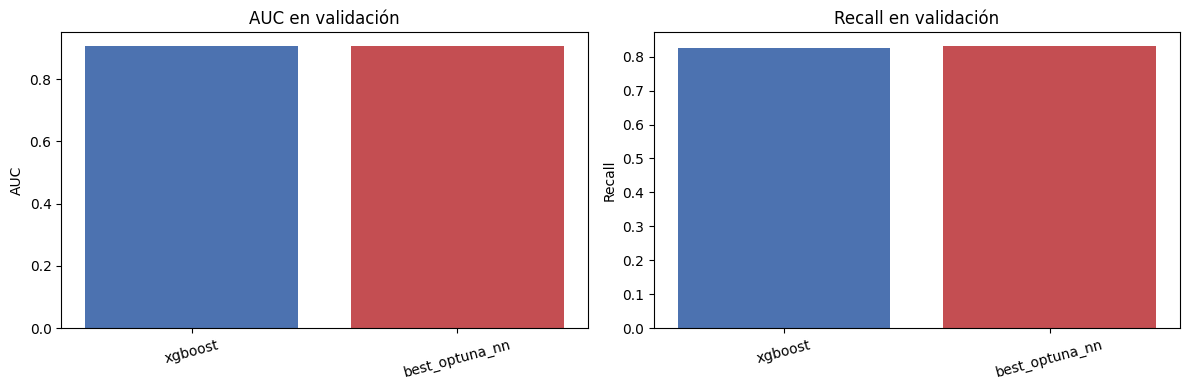

Mejor modelo entre árboles y NN por AUC: xgboost (0.9051).


In [10]:
required_objects = ["comparison_df", "best_tree_model_row", "X_valid", "y_valid"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Faltan variables para comparar con el modelo de NN. Ejecutar primero las partes 1 a 5 completas: "
        + ", ".join(missing_objects)
    )

try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError(
        "No se pudo importar tensorflow. Es necesario para cargar models/NN_best_optuna."
    ) from exc


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists():
            return candidate
    raise RuntimeError("No se pudo encontrar la raíz del repo desde el directorio actual.")


def load_saved_model_predict_fn(model_path: Path):
    saved_model = tf.saved_model.load(str(model_path))
    serve_fn = saved_model.signatures.get("serve") or saved_model.signatures.get("serving_default")
    if serve_fn is None:
        raise RuntimeError("El SavedModel no expone firmas 'serve' ni 'serving_default'.")
    return serve_fn


def predict_saved_nn_scores(serve_fn, X_frame: pd.DataFrame) -> np.ndarray:
    inputs = tf.convert_to_tensor(X_frame.to_numpy(dtype=np.float32))

    try:
        outputs = serve_fn(inputs)
    except TypeError:
        keyword_inputs = serve_fn.structured_input_signature[1]
        if not keyword_inputs:
            raise
        input_name = next(iter(keyword_inputs))
        outputs = serve_fn(**{input_name: inputs})

    if isinstance(outputs, dict):
        output_tensor = next(iter(outputs.values()))
    else:
        output_tensor = outputs

    return np.asarray(output_tensor).reshape(-1)


PROJECT_ROOT = find_project_root()
NN_MODEL_PATH = PROJECT_ROOT / "models" / "NN_best_optuna"

if not NN_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el modelo exportado en {NN_MODEL_PATH}. Ejecutar la sección de guardado en NN_extendido.ipynb."
    )

nn_predict_fn = load_saved_model_predict_fn(NN_MODEL_PATH)
nn_scores = predict_saved_nn_scores(nn_predict_fn, X_valid)
nn_pred = (nn_scores >= 0.5).astype(np.int8)

nn_best_optuna_summary = {
    "model": "best_optuna_nn",
    "source": "NN_extendido / models/NN_best_optuna",
    "artifact_path": str(NN_MODEL_PATH.resolve()),
    "accuracy": float(accuracy_score(y_valid, nn_pred)),
    "precision": float(precision_score(y_valid, nn_pred, zero_division=0)),
    "recall": float(recall_score(y_valid, nn_pred, zero_division=0)),
    "f1": float(f1_score(y_valid, nn_pred, zero_division=0)),
    "auc": float(roc_auc_score(y_valid, nn_scores)),
}

best_tree_summary = {
    "model": str(best_tree_model_row["model"]),
    "source": str(best_tree_model_row["source"]),
    "artifact_path": "-",
    "accuracy": float(best_tree_model_row["accuracy"]),
    "precision": float(best_tree_model_row["precision"]),
    "recall": float(best_tree_model_row["recall"]),
    "f1": float(best_tree_model_row["f1"]),
    "auc": float(best_tree_model_row["auc"]),
}

nn_vs_tree_df = pd.DataFrame([best_tree_summary, nn_best_optuna_summary])
tree_reference_row = nn_vs_tree_df.loc[nn_vs_tree_df["model"] == best_tree_summary["model"]].iloc[0]

for metric in ["accuracy", "precision", "recall", "f1", "auc"]:
    nn_vs_tree_df[f"delta_{metric}_vs_best_tree"] = (
        nn_vs_tree_df[metric] - float(tree_reference_row[metric])
    )

ranking_df = nn_vs_tree_df.sort_values(["auc", "f1"], ascending=False).reset_index(drop=True)

comparison_columns = [
    "model",
    "source",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc",
    "delta_auc_vs_best_tree",
    "delta_recall_vs_best_tree",
]

print("Comparación entre el mejor modelo de árboles y el mejor modelo de NN:")
display(ranking_df[comparison_columns].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bar_colors = ["#4C72B0", "#C44E52"][: len(ranking_df)]

axes[0].bar(ranking_df["model"], ranking_df["auc"], color=bar_colors)
axes[0].set_title("AUC en validación")
axes[0].set_ylabel("AUC")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(ranking_df["model"], ranking_df["recall"], color=bar_colors)
axes[1].set_title("Recall en validación")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

overall_best_row = ranking_df.iloc[0]
print(
    f"Mejor modelo entre árboles y NN por AUC: {overall_best_row['model']} "
    f"({overall_best_row['auc']:.4f})."
)


## Parte 7 - Investigación de hiperparámetros para XGBoost

En esta sección se exploran únicamente los hiperparámetros pedidos para `XGBoost`:

- `learning_rate`
- `n_estimators`
- `scale_pos_weight`
- `max_depth`

La búsqueda mantiene fijos el resto de los parámetros para poder observar mejor el efecto de esos cuatro ejes sobre `ROC AUC`.

Resultados completos de la búsqueda de hiperparámetros para XGBoost:


,param_learning_rate,param_n_estimators,param_max_depth,param_scale_pos_weight,mean_train_score,std_train_score,mean_test_score,std_test_score,rank_test_score
0,0.05,400,6,1.5346,0.9274,0.0004,0.9080,0.0015,1
1,0.05,400,6,1.9183,0.9275,0.0004,0.9080,0.0015,2
2,0.05,400,6,2.3019,0.9275,0.0003,0.9079,0.0015,3
3,0.10,200,6,1.5346,0.9272,0.0003,0.9077,0.0016,4
4,0.10,200,6,1.9183,0.9271,0.0003,0.9077,0.0015,5
5,0.10,400,6,1.5346,0.9418,0.0002,0.9076,0.0015,6
6,0.10,400,6,1.9183,0.9417,0.0003,0.9076,0.0014,7
7,0.10,200,6,2.3019,0.9272,0.0003,0.9075,0.0015,8
8,0.10,400,6,2.3019,0.9419,0.0003,0.9074,0.0015,9
9,0.03,400,6,1.5346,0.9199,0.0004,0.9070,0.0015,10


Mejor combinación encontrada para XGBoost:


,model,cv_train_auc_mean,cv_train_auc_std,cv_valid_auc_mean,cv_valid_auc_std,cv_gap_auc,accuracy,precision,recall,f1,auc,best_learning_rate,best_n_estimators,best_max_depth,best_scale_pos_weight
0,xgboost_tuned,0.9274,0.0004,0.908,0.0015,0.0194,0.8311,0.7347,0.7937,0.7631,0.9057,0.05,400,6,1.5346


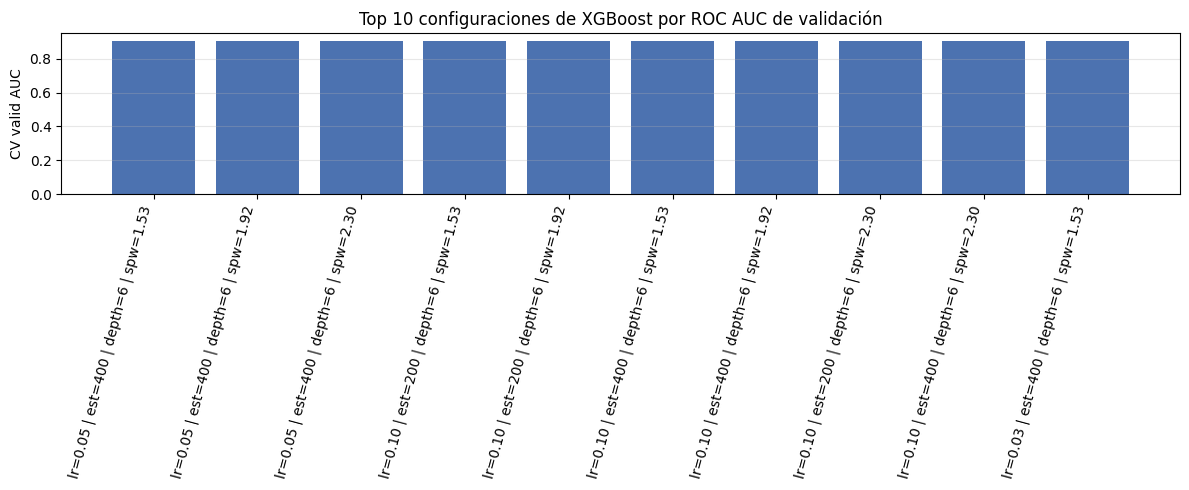

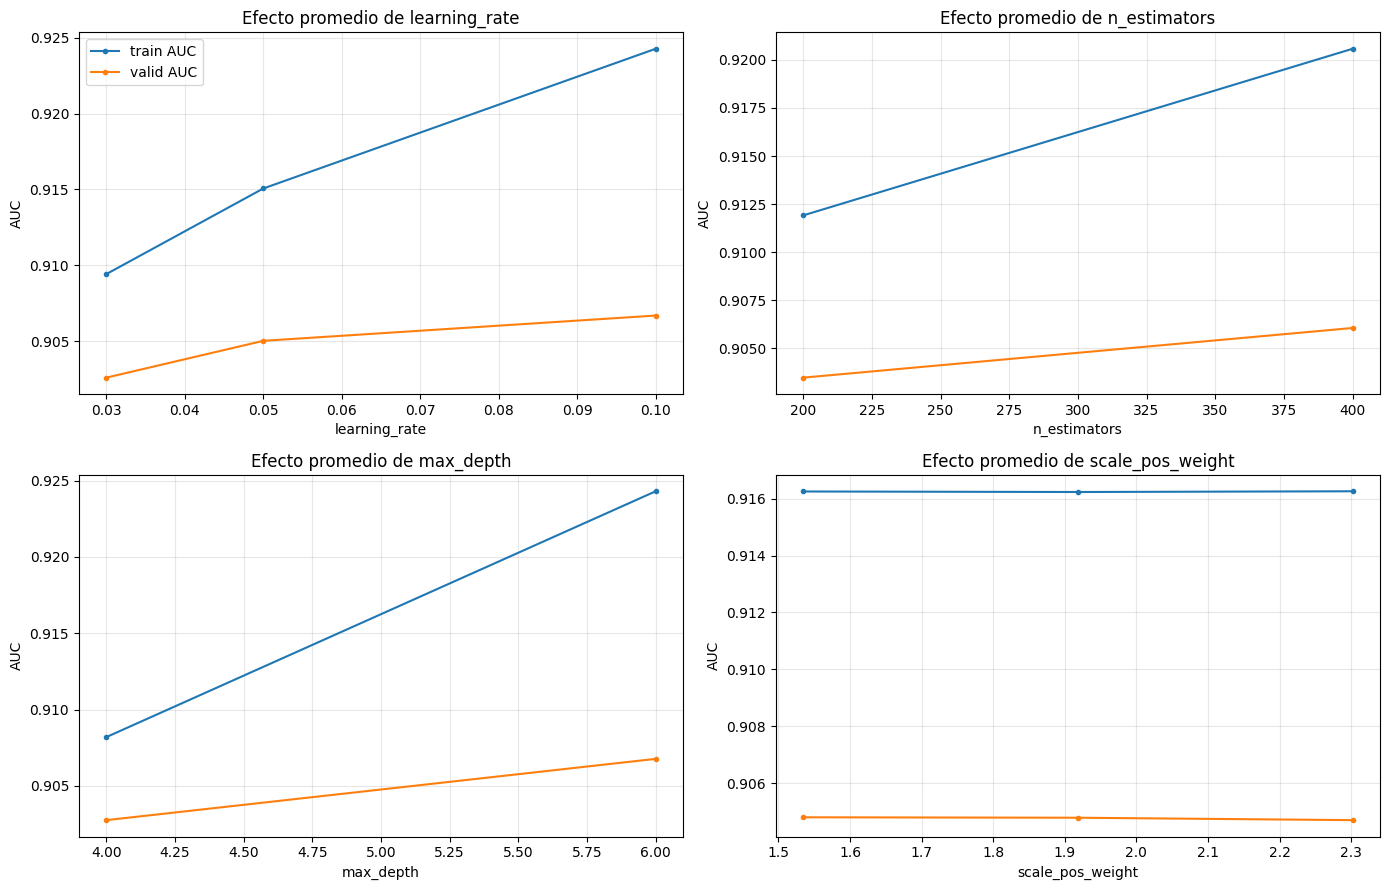

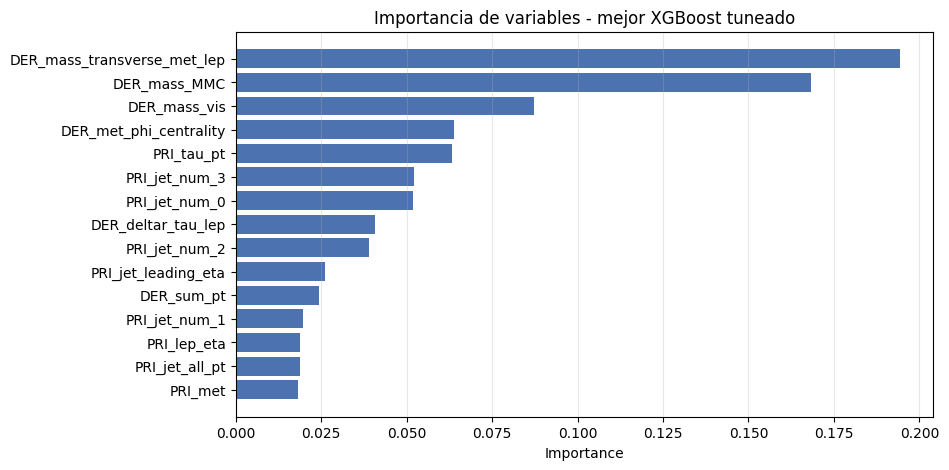

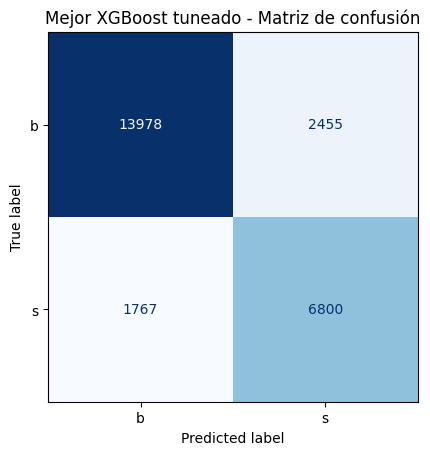

In [5]:
if not XGBOOST_AVAILABLE:
    print(
        "No se pudo importar xgboost. Esta investigación se omite por ahora. "
        "Para ejecutarla, instalar con `%pip install xgboost`."
    )
else:
    XGB_TUNING_PARAM_GRID = {
        "learning_rate": [0.03, 0.05, 0.1],
        "n_estimators": [200, 400],
        "max_depth": [4, 6],
        "scale_pos_weight": [
            round(scale_pos_weight * 0.8, 4),
            round(scale_pos_weight, 4),
            round(scale_pos_weight * 1.2, 4),
        ],
    }

    tuned_xgb_base = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=SEED,
        subsample=0.9,
        colsample_bytree=0.9,
        tree_method="hist",
        n_jobs=-1,
    )

    xgb_grid_search = GridSearchCV(
        estimator=tuned_xgb_base,
        param_grid=XGB_TUNING_PARAM_GRID,
        cv=make_cv(),
        scoring="roc_auc",
        return_train_score=True,
        n_jobs=-1,
    )

    xgb_grid_search.fit(X_train, y_train)

    xgb_tuning_results_df = pd.DataFrame(xgb_grid_search.cv_results_).sort_values(
        ["mean_test_score", "mean_train_score"],
        ascending=False,
    ).reset_index(drop=True)

    for column in [
        "param_learning_rate",
        "param_n_estimators",
        "param_max_depth",
        "param_scale_pos_weight",
    ]:
        xgb_tuning_results_df[column] = pd.to_numeric(xgb_tuning_results_df[column])

    best_xgboost_tuned = xgb_grid_search.best_estimator_
    best_xgboost_tuned_eval = evaluate_classifier(best_xgboost_tuned, X_valid, y_valid, "xgboost_tuned")
    best_idx = xgb_grid_search.best_index_
    best_xgboost_tuned_cv_summary = {
        "model": "xgboost_tuned",
        "cv_train_auc_mean": float(xgb_grid_search.cv_results_["mean_train_score"][best_idx]),
        "cv_train_auc_std": float(xgb_grid_search.cv_results_["std_train_score"][best_idx]),
        "cv_valid_auc_mean": float(xgb_grid_search.cv_results_["mean_test_score"][best_idx]),
        "cv_valid_auc_std": float(xgb_grid_search.cv_results_["std_test_score"][best_idx]),
        "cv_gap_auc": float(
            xgb_grid_search.cv_results_["mean_train_score"][best_idx]
            - xgb_grid_search.cv_results_["mean_test_score"][best_idx]
        ),
    }

    best_xgboost_tuned_summary_df = pd.DataFrame([
        {
            **best_xgboost_tuned_cv_summary,
            **best_xgboost_tuned_eval,
            "best_learning_rate": float(xgb_grid_search.best_params_["learning_rate"]),
            "best_n_estimators": int(xgb_grid_search.best_params_["n_estimators"]),
            "best_max_depth": int(xgb_grid_search.best_params_["max_depth"]),
            "best_scale_pos_weight": float(xgb_grid_search.best_params_["scale_pos_weight"]),
        }
    ])

    xgb_tuning_results_df["config_label"] = xgb_tuning_results_df.apply(
        lambda row: (
            f"lr={row['param_learning_rate']:.2f} | "
            f"est={int(row['param_n_estimators'])} | "
            f"depth={int(row['param_max_depth'])} | "
            f"spw={row['param_scale_pos_weight']:.2f}"
        ),
        axis=1,
    )

    print("Resultados completos de la búsqueda de hiperparámetros para XGBoost:")
    display(
        xgb_tuning_results_df[[
            "param_learning_rate",
            "param_n_estimators",
            "param_max_depth",
            "param_scale_pos_weight",
            "mean_train_score",
            "std_train_score",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]].round(4)
    )

    print("Mejor combinación encontrada para XGBoost:")
    display(best_xgboost_tuned_summary_df.round(4))

    top_xgb_configs_df = xgb_tuning_results_df.head(10).copy()

    plt.figure(figsize=(12, 5))
    plt.bar(top_xgb_configs_df["config_label"], top_xgb_configs_df["mean_test_score"], color="#4C72B0")
    plt.xticks(rotation=75, ha="right")
    plt.ylabel("CV valid AUC")
    plt.title("Top 10 configuraciones de XGBoost por ROC AUC de validación")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    def plot_xgb_param_effect(results_df: pd.DataFrame, param_name: str, ax, x_label: str) -> None:
        grouped = results_df.groupby(f"param_{param_name}")[["mean_train_score", "mean_test_score"]].mean().reset_index()
        grouped = grouped.sort_values(f"param_{param_name}")
        x_values = grouped[f"param_{param_name}"]

        ax.plot(x_values, grouped["mean_train_score"], ".-", label="train AUC")
        ax.plot(x_values, grouped["mean_test_score"], ".-", label="valid AUC")
        ax.set_title(x_label)
        ax.set_xlabel(param_name)
        ax.set_ylabel("AUC")
        ax.grid(alpha=0.3)

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    plot_xgb_param_effect(xgb_tuning_results_df, "learning_rate", axes[0, 0], "Efecto promedio de learning_rate")
    plot_xgb_param_effect(xgb_tuning_results_df, "n_estimators", axes[0, 1], "Efecto promedio de n_estimators")
    plot_xgb_param_effect(xgb_tuning_results_df, "max_depth", axes[1, 0], "Efecto promedio de max_depth")
    plot_xgb_param_effect(xgb_tuning_results_df, "scale_pos_weight", axes[1, 1], "Efecto promedio de scale_pos_weight")
    axes[0, 0].legend()
    plt.tight_layout()
    plt.show()

    plot_top_feature_importances(best_xgboost_tuned, X_train.columns, "Importancia de variables - mejor XGBoost tuneado")
    display_confusion_matrix(best_xgboost_tuned, X_valid, y_valid, "Mejor XGBoost tuneado - Matriz de confusión")


## Parte 8 - Mejor XGBoost vs `best_optuna` de NN

Una vez encontrada la mejor combinación de hiperparámetros para `XGBoost`, esta sección la compara directamente contra `best_optuna` de redes neuronales cargado desde `models/NN_best_optuna`.

La idea es responder una pregunta concreta: si ajustamos bien `XGBoost`, ¿queda por encima o por debajo del mejor modelo de NN en el mismo conjunto de validación?

I0000 00:00:1776641320.142253    3810 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1776641320.791513    3810 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/lib/python3/dist-packages/requests/__init__.py:87: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (4.0.0) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({}) doesn't match a supported "
I0000 00:00:1776641322.787757    3810 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Comparación entre el mejor XGBoost tuneado y best_optuna de NN:


E0000 00:00:1776641323.326048    3810 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1776641323.326579    4866 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1776641323.354413    3810 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
W0000 00:00:1776641323.466099    4894 cpu_allocator_impl.cc:82] Allocation of 32000000 exceeds 10% of free system memory.
W0000 00:00:1776641323.514523    4894 cpu_allocator_

,model,source,accuracy,precision,recall,f1,auc,delta_auc_vs_best_xgboost,delta_recall_vs_best_xgboost
0,xgboost_tuned_best,"lr=0.05, estimators=400, depth=6, spw=1.5346",0.8311,0.7347,0.7937,0.7631,0.9057,0.0000,0.0000
1,best_optuna_nn,NN_extendido / models/NN_best_optuna,0.8214,0.7025,0.8304,0.7611,0.9050,-0.0007,0.0367


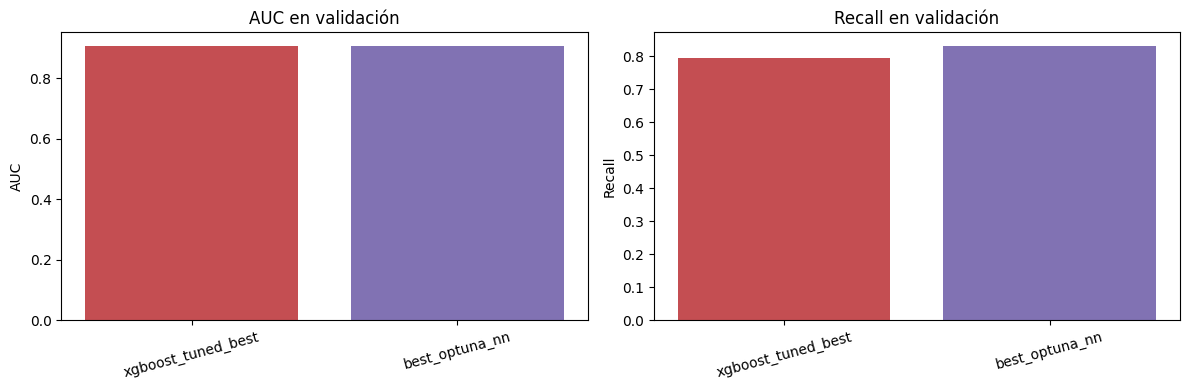

Mejor modelo entre XGBoost tuneado y best_optuna de NN por AUC: xgboost_tuned_best (0.9057).


In [6]:
if not XGBOOST_AVAILABLE:
    print(
        "No se pudo importar xgboost. La comparación final entre XGBoost tuneado y NN se omite por ahora."
    )
else:
    required_objects = ["best_xgboost_tuned_eval", "X_valid", "y_valid"]
    missing_objects = [name for name in required_objects if name not in globals()]
    if missing_objects:
        raise RuntimeError(
            "Faltan variables para comparar XGBoost tuneado con el modelo de NN. Ejecutar primero la Parte 7 completa: "
            + ", ".join(missing_objects)
        )

    try:
        import tensorflow as tf
    except ImportError as exc:
        raise ImportError(
            "No se pudo importar tensorflow. Es necesario para cargar models/NN_best_optuna."
        ) from exc

    if "find_project_root" not in globals():
        def find_project_root(start: Path | None = None) -> Path:
            current = (start or Path.cwd()).resolve()
            for candidate in [current, *current.parents]:
                if (candidate / "roadmap.md").exists():
                    return candidate
            raise RuntimeError("No se pudo encontrar la raíz del repo desde el directorio actual.")

    if "load_saved_model_predict_fn" not in globals():
        def load_saved_model_predict_fn(model_path: Path):
            saved_model = tf.saved_model.load(str(model_path))
            serve_fn = saved_model.signatures.get("serve") or saved_model.signatures.get("serving_default")
            if serve_fn is None:
                raise RuntimeError("El SavedModel no expone firmas 'serve' ni 'serving_default'.")
            return serve_fn

    if "predict_saved_nn_scores" not in globals():
        def predict_saved_nn_scores(serve_fn, X_frame: pd.DataFrame) -> np.ndarray:
            inputs = tf.convert_to_tensor(X_frame.to_numpy(dtype=np.float32))

            try:
                outputs = serve_fn(inputs)
            except TypeError:
                keyword_inputs = serve_fn.structured_input_signature[1]
                if not keyword_inputs:
                    raise
                input_name = next(iter(keyword_inputs))
                outputs = serve_fn(**{input_name: inputs})

            if isinstance(outputs, dict):
                output_tensor = next(iter(outputs.values()))
            else:
                output_tensor = outputs

            return np.asarray(output_tensor).reshape(-1)

    PROJECT_ROOT = find_project_root()
    NN_MODEL_PATH = PROJECT_ROOT / "models" / "NN_best_optuna"

    if not NN_MODEL_PATH.exists():
        raise FileNotFoundError(
            f"No se encontró el modelo exportado en {NN_MODEL_PATH}. Ejecutar la sección de guardado en NN_extendido.ipynb."
        )

    nn_predict_fn = load_saved_model_predict_fn(NN_MODEL_PATH)
    nn_scores = predict_saved_nn_scores(nn_predict_fn, X_valid)
    nn_pred = (nn_scores >= 0.5).astype(np.int8)

    nn_best_optuna_summary = {
        "model": "best_optuna_nn",
        "source": "NN_extendido / models/NN_best_optuna",
        "accuracy": float(accuracy_score(y_valid, nn_pred)),
        "precision": float(precision_score(y_valid, nn_pred, zero_division=0)),
        "recall": float(recall_score(y_valid, nn_pred, zero_division=0)),
        "f1": float(f1_score(y_valid, nn_pred, zero_division=0)),
        "auc": float(roc_auc_score(y_valid, nn_scores)),
    }

    tuned_xgb_summary = {
        "model": "xgboost_tuned_best",
        "source": (
            f"lr={xgb_grid_search.best_params_['learning_rate']}, "
            f"estimators={xgb_grid_search.best_params_['n_estimators']}, "
            f"depth={xgb_grid_search.best_params_['max_depth']}, "
            f"spw={xgb_grid_search.best_params_['scale_pos_weight']:.4f}"
        ),
        "accuracy": float(best_xgboost_tuned_eval["accuracy"]),
        "precision": float(best_xgboost_tuned_eval["precision"]),
        "recall": float(best_xgboost_tuned_eval["recall"]),
        "f1": float(best_xgboost_tuned_eval["f1"]),
        "auc": float(best_xgboost_tuned_eval["auc"]),
    }

    xgb_vs_nn_df = pd.DataFrame([tuned_xgb_summary, nn_best_optuna_summary])
    xgb_reference_row = xgb_vs_nn_df.loc[xgb_vs_nn_df["model"] == "xgboost_tuned_best"].iloc[0]

    for metric in ["accuracy", "precision", "recall", "f1", "auc"]:
        xgb_vs_nn_df[f"delta_{metric}_vs_best_xgboost"] = (
            xgb_vs_nn_df[metric] - float(xgb_reference_row[metric])
        )

    xgb_vs_nn_ranking_df = xgb_vs_nn_df.sort_values(["auc", "f1"], ascending=False).reset_index(drop=True)

    comparison_columns = [
        "model",
        "source",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "auc",
        "delta_auc_vs_best_xgboost",
        "delta_recall_vs_best_xgboost",
    ]

    print("Comparación entre el mejor XGBoost tuneado y best_optuna de NN:")
    display(xgb_vs_nn_ranking_df[comparison_columns].round(4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    bar_colors = ["#C44E52", "#8172B3"][: len(xgb_vs_nn_ranking_df)]

    axes[0].bar(xgb_vs_nn_ranking_df["model"], xgb_vs_nn_ranking_df["auc"], color=bar_colors)
    axes[0].set_title("AUC en validación")
    axes[0].set_ylabel("AUC")
    axes[0].tick_params(axis="x", rotation=15)

    axes[1].bar(xgb_vs_nn_ranking_df["model"], xgb_vs_nn_ranking_df["recall"], color=bar_colors)
    axes[1].set_title("Recall en validación")
    axes[1].set_ylabel("Recall")
    axes[1].tick_params(axis="x", rotation=15)

    plt.tight_layout()
    plt.show()

    overall_best_row = xgb_vs_nn_ranking_df.iloc[0]
    print(
        f"Mejor modelo entre XGBoost tuneado y best_optuna de NN por AUC: {overall_best_row['model']} "
        f"({overall_best_row['auc']:.4f})."
    )


## Cierre

El notebook conserva la lógica del taller 3, pero ya enfocada al problema Higgs con datos procesados y una métrica de clasificación coherente.

A partir de acá, los siguientes pasos razonables serían:

- extender el ajuste fino de `RandomForest`
- ampliar la búsqueda de `XGBoost` a otros hiperparámetros como `min_child_weight`, `subsample` o `colsample_bytree`
- repetir la comparación final con otras métricas o thresholds
- o llevar el mejor modelo de árboles a una etapa de submission y comparación contra NN